In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import pprint
import copy


while "src" not in os.listdir():
    os.chdir('..')

from src.reading_in import read_in_proteins
from src.scoring_and_selection import simple_text_selection
from final_code_submission.Exclusion.TEO_method import calculate_TEO

FILEPATH = "data/raw/protein.links.v12.0.txt.gz"
G = read_in_proteins(include_essential_proteins=False, connected=True)


## Good/bad proteins

In [2]:
bad = {"YPR119W", "YDL160C", "YNL298W", "YPR100W", "YGR184C", "YJL189W", "YGL049C", "YBR271W", "YER120W", "YLR221C", "YBR271W", "YBL028C", "YGR118W", "YDL136W", "YDL191W ", "YGR034W", "YLR344W", "YBR010W", "YJL177W", "YGR220C", "YIL018W", "YGR271C-A", "YDR213W", "YBR111W-A", "YDR159W", "YPL178W", "YDR138W", "YLL041C", "YNL064C"}
yes = {"YHL027W", "YDR320C", "YOR042W", "YKR039W"}

## Word analysis Testing

In [ ]:
# Sources python modules mygene for stuff
for sets in [bad, yes]:
    count = 0
    for protein in sets:
        if not simple_text_selection(protein_name=protein):
            count += 1
    if sets == bad:
        print(f"{count} of {len(sets)} proteins identified as bad.")
    else:
        print(f"{count} of {len(sets)} proteins identified as good.")
    


aaaaa
18 of 28 proteins identified as bad.
0 of 4 proteins identified as good.


## TEO Testing

In [ ]:
### feeding teo
# download data from https://drive.google.com/file/d/1EMlg9CR6-2C8f6hM6fRU9i5zA9XNcfhb/view?usp=drive_link
expression_filepath = "final_code_submission/Exclusion/GSE3431_gene_expression.csv"
gaf_filepath = "final_code_submission/Exclusion/ppi-data/go/YEAST-mod.gaf"
go_obo_filepath = "final_code_submission/Exclusion/ppi-data/go/go-basic.obo"
teo = calculate_TEO(G, expression_filepath,gaf_filepath,go_obo_filepath)

Expression profiles for 3,948/4,209 graph nodes
GAF annotation rows retained for aspect P: 42,115
Graph nodes with at least one matched GO annotation: 4,202/4,209
Matched annotation rows: 26,763
Calculated Wang GO similarities for 40,992/41,037 graph edges


In [4]:
### Creating scores for good and bad proteins
bad_scores = []
good_scores = []

for protein in bad:
    try:
#        print(protein,teo[protein])
        if not np.isnan(teo[protein]):
            bad_scores.append(teo[protein])
    except:
        print(f"{protein} had an error")

for protein in yes:
    try:
#        print(protein,teo[protein])
        if not np.isnan(teo[protein]):
            good_scores.append(teo[protein])
    except:
        print(f"{protein} had an error")

YDL191W  had an error


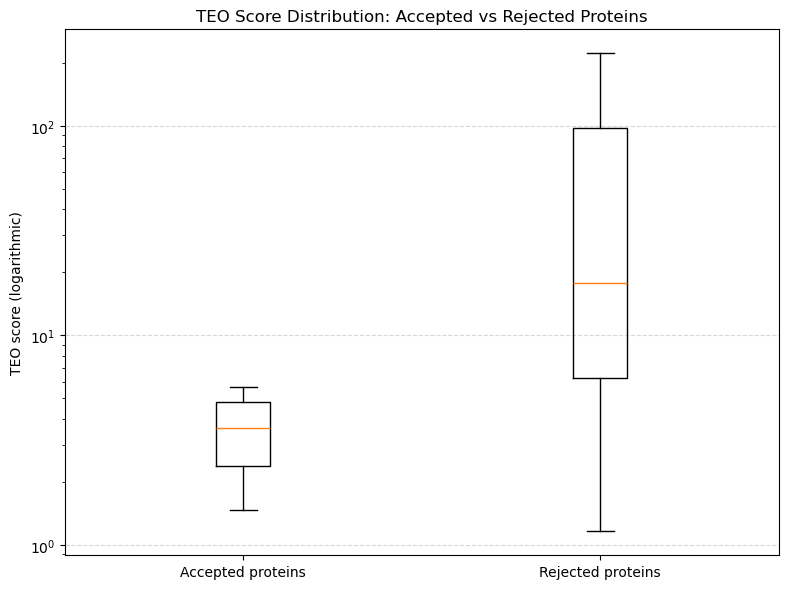

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.boxplot(
    [good_scores, bad_scores],
    tick_labels=["Accepted proteins", "Rejected proteins"],
    showfliers=True
)

plt.ylabel("TEO score (logarithmic)")
plt.title("TEO Score Distribution: Accepted vs Rejected Proteins")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.yscale("log")
plt.savefig("final_code_submission/Exclusion/Good vs Bad Proteins.png")
plt.show()